In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine

engine = create_engine("postgresql+psycopg2://localhost/olist")
sns.set_theme(style="whitegrid")

In [4]:
pip freeze > requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [6]:
orders = pd.read_sql("SELECT * FROM fact_orders", engine)
print(orders.shape)
orders.head()

(96211, 17)


,order_id,customer_id,order_date,delivered_date,estimated_date,revenue,freight_value,n_items,n_sellers,main_payment_type,installments,review_score,is_bad_review,days_vs_estimate,is_late,delay_bucket,delivery_days
0,00010242fe8c5a6d1ba2dd792cb16214,3ce436f183e68e07877b285a838db11a,2017-09-13,2017-09-20,2017-09-29,58.90,13.29,1,1,credit_card,2,5.0,False,-9.0,False,1 Early,7.614421
1,00018f77f2f0320c557190d7a144bdd3,f6dd3ec061db4e3987629fe6b26e5cce,2017-04-26,2017-05-12,2017-05-15,239.90,19.93,1,1,credit_card,3,4.0,False,-3.0,False,1 Early,16.216181
2,000229ec398224ef6ca0657da4fc703e,6489ae5e4333f3693df5ad4372dab6d3,2018-01-14,2018-01-22,2018-02-05,199.00,17.87,1,1,credit_card,5,5.0,False,-14.0,False,1 Early,7.948437
3,00024acbcdf0a6daa1e931b038114c75,d4eb9395c8c0431ee92fce09860c5a06,2018-08-08,2018-08-14,2018-08-20,12.99,12.79,1,1,credit_card,2,4.0,False,-6.0,False,1 Early,6.147269
4,00042b26cf59d7ce69dfabb4e55b4fd9,58dbd0b2d70206bf40e62cd34e84d795,2017-02-04,2017-03-01,2017-03-17,199.90,18.14,1,1,credit_card,3,5.0,False,-16.0,False,1 Early,25.114352


In [7]:
orders.info()
orders.isna().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 96211 entries, 0 to 96210
Data columns (total 17 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   order_id           96211 non-null  object 
 1   customer_id        96211 non-null  object 
 2   order_date         96211 non-null  object 
 3   delivered_date     96203 non-null  object 
 4   estimated_date     96211 non-null  object 
 5   revenue            96211 non-null  float64
 6   freight_value      96211 non-null  float64
 7   n_items            96211 non-null  int64  
 8   n_sellers          96211 non-null  int64  
 9   main_payment_type  96211 non-null  object 
 10  installments       96211 non-null  int64  
 11  review_score       95568 non-null  float64
 12  is_bad_review      95568 non-null  object 
 13  days_vs_estimate   96203 non-null  float64
 14  is_late            96203 non-null  object 
 15  delay_bucket       96203 non-null  object 
 16  delivery_days      962

order_id               0
customer_id            0
order_date             0
delivered_date         8
estimated_date         0
revenue                0
freight_value          0
n_items                0
n_sellers              0
main_payment_type      0
installments           0
review_score         643
is_bad_review        643
days_vs_estimate       8
is_late                8
delay_bucket           8
delivery_days          8
dtype: int64

In [8]:
for col in ["order_date", "delivered_date", "estimated_date"]:
    orders[col] = pd.to_datetime(orders[col])

orders["is_bad_review"] = orders["is_bad_review"].astype("boolean")
orders["is_late"] = orders["is_late"].astype("boolean")

orders.dtypes

order_id                     object
customer_id                  object
order_date           datetime64[ns]
delivered_date       datetime64[ns]
estimated_date       datetime64[ns]
revenue                     float64
freight_value               float64
n_items                       int64
n_sellers                     int64
main_payment_type            object
installments                  int64
review_score                float64
is_bad_review               boolean
days_vs_estimate            float64
is_late                     boolean
delay_bucket                 object
delivery_days               float64
dtype: object

In [9]:
orders[["revenue", "freight_value", "n_items", "n_sellers",
        "installments", "review_score", "days_vs_estimate",
        "delivery_days"]].describe().round(2)

,revenue,freight_value,n_items,n_sellers,installments,review_score,days_vs_estimate,delivery_days
count,96211.00,96211.00,96211.00,96211.00,96211.00,95568.00,96203.00,96203.00
mean,137.00,22.78,1.14,1.01,2.93,4.16,-11.81,12.54
std,209.11,21.57,0.54,0.12,2.71,1.28,10.09,9.53
min,0.85,0.00,1.00,1.00,0.00,1.00,-147.00,0.53
25%,45.90,13.85,1.00,1.00,1.00,4.00,-17.00,6.76
50%,86.50,17.17,1.00,1.00,2.00,5.00,-12.00,10.21
75%,149.90,24.01,1.00,1.00,4.00,5.00,-7.00,15.68
max,13440.00,1794.96,21.00,5.00,24.00,5.00,188.00,209.63


In [10]:
print((orders["installments"] == 0).sum())
orders[orders["installments"] == 0]["main_payment_type"].value_counts()

2


main_payment_type
credit_card    2
Name: count, dtype: int64

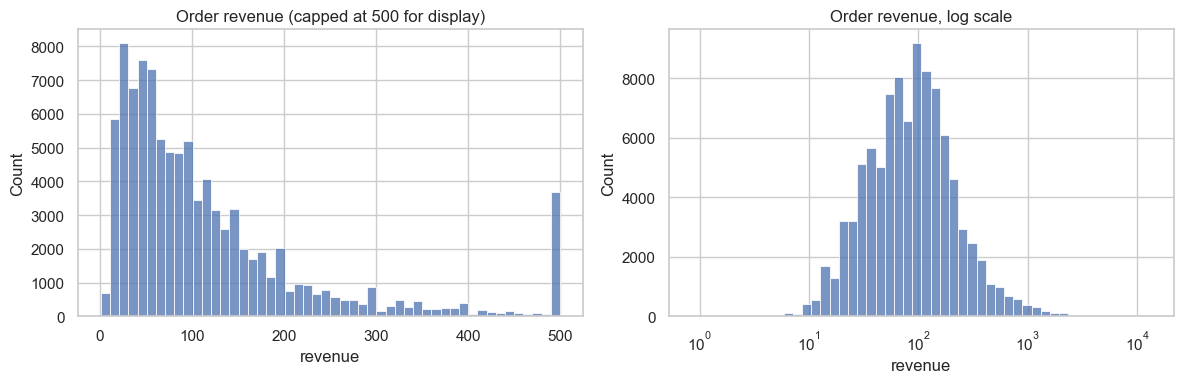

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(orders["revenue"].clip(upper=500), bins=50, ax=axes[0])
axes[0].set_title("Order revenue (capped at 500 for display)")
sns.histplot(orders["revenue"], bins=50, log_scale=True, ax=axes[1])
axes[1].set_title("Order revenue, log scale")
plt.tight_layout()
plt.show()

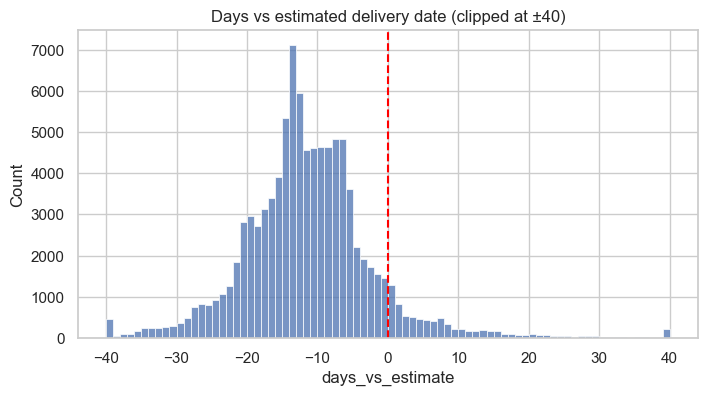

In [12]:
plt.figure(figsize=(8, 4))
sns.histplot(orders["days_vs_estimate"].dropna().clip(-40, 40), bins=80)
plt.axvline(0, color="red", linestyle="--")
plt.title("Days vs estimated delivery date (clipped at ±40)")
plt.show()

In [ ]:
bucket = (orders.dropna(subset=["review_score", "delay_bucket"])
          .groupby("delay_bucket")
          .agg(orders=("order_id", "count"),
               avg_review=("review_score", "mean"),
               pct_bad=("is_bad_review", "mean")))
bucket["pct_bad"] = (bucket["pct_bad"] * 100).round(1)
bucket["avg_review"] = bucket["avg_review"].round(2)
bucket




,orders,avg_review,pct_bad
delay_bucket,,,
1 Early,87902,4.29,9.2
2 On time,1280,4.03,12.4
3 Late 1-3 days,1851,3.29,32.1
4 Late 4-7 days,1748,2.10,67.6
5 Late 8+ days,2779,1.70,79.3


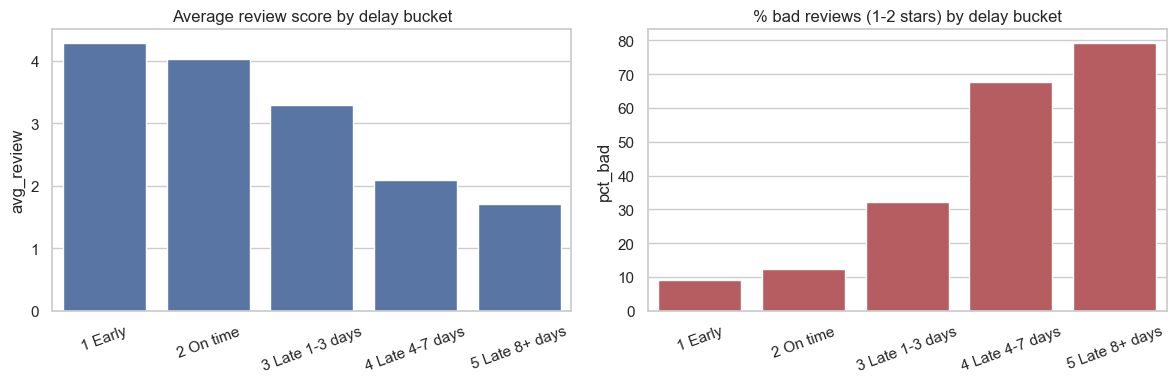

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=bucket.index, y=bucket["avg_review"], ax=axes[0], color="#4c72b0")
axes[0].set_title("Average review score by delay bucket")
axes[0].set_xlabel("")
sns.barplot(x=bucket.index, y=bucket["pct_bad"], ax=axes[1], color="#c44e52")
axes[1].set_title("% bad reviews (1-2 stars) by delay bucket")
axes[1].set_xlabel("")
for ax in axes:
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

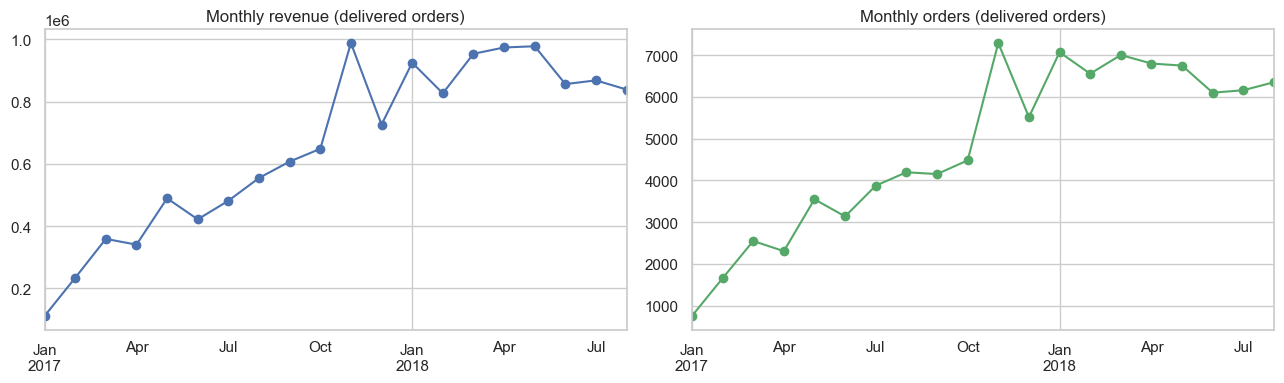

In [15]:
monthly = (orders.assign(month=orders["order_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month")
           .agg(orders=("order_id", "count"), revenue=("revenue", "sum")))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
monthly["revenue"].plot(ax=axes[0], marker="o")
axes[0].set_title("Monthly revenue (delivered orders)")
monthly["orders"].plot(ax=axes[1], marker="o", color="#55a868")
axes[1].set_title("Monthly orders (delivered orders)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

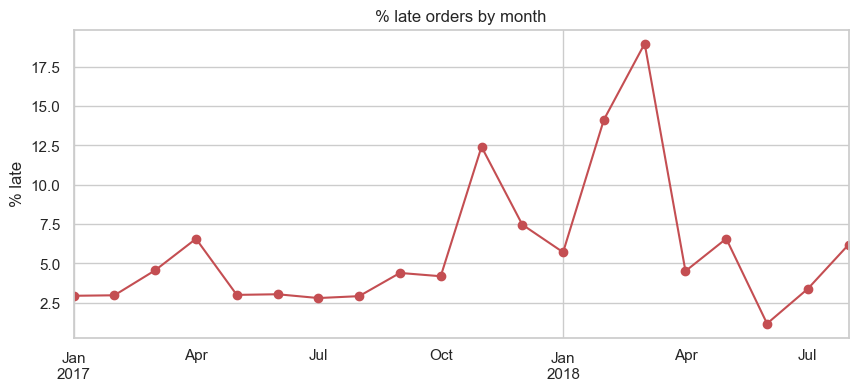

In [16]:
late_month = (orders.dropna(subset=["is_late"])
              .assign(month=lambda d: d["order_date"].dt.to_period("M").dt.to_timestamp())
              .groupby("month")["is_late"].mean() * 100)

plt.figure(figsize=(10, 4))
late_month.plot(marker="o", color="#c44e52")
plt.title("% late orders by month")
plt.ylabel("% late")
plt.xlabel("")
plt.show()